In [8]:
import os
import cv2
import glob
from tqdm import tqdm

# 1. Inject Kaggle Credentials (MUST happen before importing kaggle)
os.environ['KAGGLE_USERNAME'] = "battusainithin"
os.environ['KAGGLE_KEY'] = "53994d267491d7341149eb058196e71f"

import kaggle
from mtcnn import MTCNN

# 2. Define Permanent Storage Paths (Google Drive)
drive_root = '/content/drive/MyDrive/Dissertation'
raw_data_dir = os.path.join(drive_root, 'raw_videos')
processed_data_dir = os.path.join(drive_root, 'dataset')
real_dir = os.path.join(processed_data_dir, 'real')
fake_dir = os.path.join(processed_data_dir, 'fake')

for d in [raw_data_dir, real_dir, fake_dir]:
    os.makedirs(d, exist_ok=True)

# 3. Robust Kaggle Download & Auto-Unzip
print("Starting dataset download...")
dataset_slug = 'xdxd003/ff-c23'

print(f"Downloading and unzipping {dataset_slug} to {raw_data_dir}...")
# Setting unzip=True uses Kaggle's native extractor, avoiding the lz4 closed file bug
kaggle.api.dataset_download_files(dataset_slug, path=raw_data_dir, unzip=True)
print("Download and Unzipping complete.")

# 4. Locate the Extracted Videos
print("Scanning for extracted .mp4 files...")
mp4_files = glob.glob(f"{raw_data_dir}/**/*.mp4", recursive=True)

if not mp4_files:
    print("No .mp4 files found! Check the raw_videos directory.")
else:
    print(f"Success! Found {len(mp4_files)} videos. Starting MTCNN extraction...")

    # 5. Initialize MTCNN Preprocessing Pipeline
    detector = MTCNN()
    target_size = (380, 380)

    def extract_faces(video_path, output_dir, max_frames=30):
        vidcap = cv2.VideoCapture(video_path)
        success, image = vidcap.read()
        count = 0
        saved = 0
        vid_name = os.path.splitext(os.path.basename(video_path))[0]

        while success and saved < max_frames:
            # Process every 5th frame to avoid redundant data
            if count % 5 == 0:
                rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                results = detector.detect_faces(rgb_image)

                if results:
                    x, y, width, height = results[0]['box']
                    margin = int(width * 0.1)

                    # Ensure bounding box doesn't go outside image dimensions
                    x, y = max(0, x - margin), max(0, y - margin)
                    x_end = min(image.shape[1], x + width + 2*margin)
                    y_end = min(image.shape[0], y + height + 2*margin)

                    cropped_face = image[y:y_end, x:x_end]

                    if cropped_face.size != 0:
                        resized_face = cv2.resize(cropped_face, target_size)
                        out_filename = os.path.join(output_dir, f"{vid_name}_frame{count}.jpg")
                        cv2.imwrite(out_filename, resized_face)
                        saved += 1

Starting dataset download...
Dataset URL: https://www.kaggle.com/datasets/xdxd003/ff-c23
Download and Unzipping complete.
Scanning for extracted .mp4 files...


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Success! Found 7000 videos. Starting MTCNN extraction...


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


In [2]:
import os
import glob

real_dir = '/content/drive/MyDrive/Dissertation/dataset/real'
fake_dir = '/content/drive/MyDrive/Dissertation/dataset/fake'

real_images = glob.glob(f"{real_dir}/*.*")
fake_images = glob.glob(f"{fake_dir}/*.*")

print(f"Images in REAL folder: {len(real_images)}")
print(f"Images in FAKE folder: {len(fake_images)}")

# If they are empty, let's see where the raw videos actually are
if len(real_images) == 0 and len(fake_images) == 0:
    raw_dir = '/content/drive/MyDrive/Dissertation/raw_videos'
    all_videos = glob.glob(f"{raw_dir}/**/*.mp4", recursive=True)
    print(f"\nWe have {len(all_videos)} raw videos.")
    if len(all_videos) > 0:
        print("Here are the first 5 video paths so we can see how they are named:")
        for v in all_videos[:5]:
            print(v)

Images in REAL folder: 0
Images in FAKE folder: 0

We have 0 raw videos.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

import glob
real_images = glob.glob('/content/drive/MyDrive/Dissertation/dataset/real/*.*')
fake_images = glob.glob('/content/drive/MyDrive/Dissertation/dataset/fake/*.*')

print(f"Images in REAL folder: {len(real_images)}")
print(f"Images in FAKE folder: {len(fake_images)}")

Mounted at /content/drive
Images in REAL folder: 0
Images in FAKE folder: 0


In [5]:
import os
import cv2
import glob
!pip install mtcnn
from tqdm import tqdm
from mtcnn import MTCNN

# 1. Define your Google Drive paths
# We will search your entire Dissertation folder for these .mp4 files
search_dir = '/content/drive/MyDrive/Dissertation'
real_dir = '/content/drive/MyDrive/Dissertation/dataset/real'
fake_dir = '/content/drive/MyDrive/Dissertation/dataset/fake'

os.makedirs(real_dir, exist_ok=True)
os.makedirs(fake_dir, exist_ok=True)

# 2. Find all MP4 files in the directory
print(f"Scanning for .mp4 files in {search_dir}...")
all_videos = glob.glob(f"{search_dir}/**/*.mp4", recursive=True)

if not all_videos:
    print("No videos found. Please check if they are saved in a different Google Drive folder.")
else:
    print(f"Found {len(all_videos)} videos! Sorting them into Real and Fake...")

    real_vids = []
    fake_vids = []

    # Sort based on the FF++ naming convention (underscore = fake)
    for vid in all_videos:
        filename = os.path.basename(vid)
        if "_" in filename:
            fake_vids.append(vid)
        else:
            real_vids.append(vid)

    print(f"Detected {len(real_vids)} REAL videos and {len(fake_vids)} FAKE videos.")

    # 3. Initialize GPU-Accelerated MTCNN
    detector = MTCNN()
    target_size = (380, 380)

    def extract_faces(video_path, output_dir, max_frames=20):
        vidcap = cv2.VideoCapture(video_path)
        success, image = vidcap.read()
        count = 0
        saved = 0
        vid_name = os.path.splitext(os.path.basename(video_path))[0]

        while success and saved < max_frames:
            # Process every 5th frame to speed things up and reduce redundant data
            if count % 5 == 0:
                rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                results = detector.detect_faces(rgb_image)

                if results:
                    # Get bounding box
                    x, y, width, height = results[0]['box']
                    margin = int(width * 0.1)

                    # Prevent cropping outside the image boundaries
                    x, y = max(0, x - margin), max(0, y - margin)
                    x_end = min(image.shape[1], x + width + 2*margin)
                    y_end = min(image.shape[0], y + height + 2*margin)

                    cropped = image[y:y_end, x:x_end]

                    if cropped.size != 0:
                        resized = cv2.resize(cropped, target_size)
                        out_filename = os.path.join(output_dir, f"{vid_name}_f{count}.jpg")
                        cv2.imwrite(out_filename, resized)
                        saved += 1
            success, image = vidcap.read()
            count += 1
        vidcap.release()

    # 4. Run the Extraction!
    # Processing a robust test batch of 40 videos (20 real, 20 fake) to get your model training quickly.
    # You can remove the "[:20]" later to process the entire dataset.
    print("Starting face extraction...")

    for vid_path in tqdm(real_vids[:20], desc="Extracting REAL Faces"):
        extract_faces(vid_path, real_dir)

    for vid_path in tqdm(fake_vids[:20], desc="Extracting FAKE Faces"):
        extract_faces(vid_path, fake_dir)

    print("\nExtraction complete! Your dataset is now populated and ready for PyTorch.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 17.0 MB/s  0:00:00
Scanning for .mp4 files in /content/drive/MyDrive/Dissertation...
Found 7000 videos! Sorting them into Real and Fake...
Detected 1000 REAL videos and 6000 FAKE videos.


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Starting face extraction...


Extracting FAKE Faces: 100%|██████████| 20/20 [11:47<00:00, 35.38s/it]


Extraction complete! Your dataset is now populated and ready for PyTorch.


In [6]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import os
from PIL import Image
from tqdm import tqdm

# 1. Dataset Loader targeting your extracted Google Drive files
class FaceForensicsDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.classes = ['real', 'fake']
        self.image_paths = []
        self.labels = []

        for idx, cls in enumerate(self.classes):
            cls_dir = os.path.join(data_dir, cls)
            if os.path.isdir(cls_dir):
                for img_name in os.listdir(cls_dir):
                    if img_name.endswith(('.png', '.jpg', '.jpeg')):
                        self.image_paths.append(os.path.join(cls_dir, img_name))
                        self.labels.append(idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32)

# 2. Spatial Attention Module (SAM)
class SpatialAttentionModule(nn.Module):
    def __init__(self):
        super(SpatialAttentionModule, self).__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        attention = torch.cat([avg_out, max_out], dim=1)
        attention = self.conv(attention)
        return x * self.sigmoid(attention)

# 3. EfficientNet-B4 + Custom Classifier
class EfficientNetWithSAM(nn.Module):
    def __init__(self, num_classes=1):
        super(EfficientNetWithSAM, self).__init__()
        # Load pre-trained baseline for transfer learning
        weights = models.EfficientNet_B4_Weights.DEFAULT
        self.efficientnet = models.efficientnet_b4(weights=weights)

        # Modify the classifier head
        in_features = self.efficientnet.classifier[1].in_features
        self.efficientnet.classifier = nn.Identity()

        self.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.efficientnet(x)
        output = self.classifier(features)
        return output.squeeze()

# 4. Training Configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

# Data augmentation mapping to dissertation methodology
train_transforms = transforms.Compose([
    transforms.Resize((380, 380)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

data_dir = '/content/drive/MyDrive/Dissertation/dataset'
dataset = FaceForensicsDataset(data_dir=data_dir, transform=train_transforms)

# Batch size set to 16 to prevent T4 GPU Out-Of-Memory errors with 380x380 resolution
dataloader = DataLoader(dataset, batch_size=16, shuffle=True, num_workers=2)

model = EfficientNetWithSAM(num_classes=1).to(device)
criterion = nn.BCELoss() # Binary Cross-Entropy for real vs fake
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
num_epochs = 5

# 5. Training Loop
if len(dataset) > 0:
    print(f"Starting training on {len(dataset)} images for {num_epochs} epochs...")
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        loop = tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")
        for images, labels in loop:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            # Convert probabilities to binary predictions (0 or 1)
            predictions = (outputs >= 0.5).float()
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            loop.set_postfix(loss=loss.item(), acc=correct/total)

        epoch_loss = running_loss / len(dataset)
        epoch_acc = correct / total
        print(f"Epoch {epoch+1} Summary -> Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}")

    # 6. Save model artifacts permanently to Drive
    save_path = '/content/drive/MyDrive/Dissertation/efficientnet_sam_c23.pth'
    torch.save(model.state_dict(), save_path)
    print(f"\nModel weights saved securely to {save_path}")
else:
    print("Dataset directory is empty. Double check the dataset paths.")

Using compute device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b4_rwightman-23ab8bcd.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b4_rwightman-23ab8bcd.pth


100%|██████████| 74.5M/74.5M [00:00<00:00, 200MB/s]


Starting training on 800 images for 5 epochs...


Epoch 1/5: 100%|██████████| 50/50 [00:33<00:00,  1.50it/s, acc=0.892, loss=0.0475]


Epoch 1 Summary -> Loss: 0.4842, Accuracy: 0.8925


Epoch 2/5: 100%|██████████| 50/50 [00:33<00:00,  1.50it/s, acc=0.978, loss=0.00179]


... (3 outputs left out)

Epoch 4/5: 100%|██████████| 50/50 [00:32<00:00,  1.53it/s, acc=0.994, loss=0.143]


Epoch 4 Summary -> Loss: 0.0154, Accuracy: 0.9938


Epoch 5/5: 100%|██████████| 50/50 [00:33<00:00,  1.51it/s, acc=0.996, loss=0.00174]


Epoch 5 Summary -> Loss: 0.0086, Accuracy: 0.9962

Model weights saved securely to /content/drive/MyDrive/Dissertation/efficientnet_sam_c23.pth


In [7]:
import torch
import torch.nn as nn
from torchvision import transforms, models
import cv2
from PIL import Image
from mtcnn import MTCNN
import numpy as np
import os

# 1. Re-declare the Architecture (Must exactly match training)
class SpatialAttentionModule(nn.Module):
    def __init__(self):
        super(SpatialAttentionModule, self).__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        attention = torch.cat([avg_out, max_out], dim=1)
        attention = self.conv(attention)
        return x * self.sigmoid(attention)

class EfficientNetWithSAM(nn.Module):
    def __init__(self, num_classes=1):
        super(EfficientNetWithSAM, self).__init__()
        # Initialize without pre-trained ImageNet weights since we are loading our own
        self.efficientnet = models.efficientnet_b4(weights=None)

        in_features = self.efficientnet.classifier[1].in_features
        self.efficientnet.classifier = nn.Identity()

        self.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.efficientnet(x)
        output = self.classifier(features)
        return output.squeeze()

# 2. Initialize Hardware and Load Weights
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Initializing inference on: {device}")

model = EfficientNetWithSAM(num_classes=1).to(device)
weights_path = '/content/drive/MyDrive/Dissertation/efficientnet_sam_c23.pth'

if os.path.exists(weights_path):
    model.load_state_dict(torch.load(weights_path, map_location=device))
    model.eval() # CRITICAL: Sets dropout and batchnorm to evaluation mode
    print("Model weights loaded successfully from Google Drive.")
else:
    print(f"Error: Weights not found at {weights_path}")

# 3. Define Inference Preprocessing (Must match training transforms exactly)
inference_transforms = transforms.Compose([
    transforms.Resize((380, 380)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

detector = MTCNN()

# 4. The Prediction Function
def analyze_video(video_path, num_frames_to_sample=5):
    if not os.path.exists(video_path):
        return f"File not found: {video_path}"

    print(f"\nAnalyzing video: {video_path}")
    vidcap = cv2.VideoCapture(video_path)
    total_frames = int(vidcap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Sample frames evenly across the video
    frame_indices = np.linspace(0, total_frames - 1, num_frames_to_sample, dtype=int)

    predictions = []

    for idx in frame_indices:
        vidcap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        success, image = vidcap.read()

        if success:
            rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            results = detector.detect_faces(rgb_image)

            if results:
                # Crop the first detected face
                x, y, width, height = results[0]['box']
                margin = int(width * 0.1)
                x, y = max(0, x - margin), max(0, y - margin)
                x_end = min(image.shape[1], x + width + 2*margin)
                y_end = min(image.shape[0], y + height + 2*margin)

                cropped_face = rgb_image[y:y_end, x:x_end]

                if cropped_face.size != 0:
                    # Convert to PIL Image for PyTorch transforms
                    pil_image = Image.fromarray(cropped_face)
                    input_tensor = inference_transforms(pil_image).unsqueeze(0).to(device)

                    # Run inference
                    with torch.no_grad():
                        score = model(input_tensor).item()
                        predictions.append(score)

    vidcap.release()

    if not predictions:
        return "Analysis failed: No faces detected in the sampled frames."

    # Aggregate results
    avg_score = sum(predictions) / len(predictions)

    # In our dataset: 0 = Real, 1 = Fake.
    # Therefore, scores closer to 1 indicate higher probability of manipulation.
    confidence = (avg_score if avg_score >= 0.5 else (1 - avg_score)) * 100
    classification = "FAKE (Manipulated)" if avg_score >= 0.5 else "REAL (Authentic)"

    print("-" * 40)
    print(f"FINAL VERDICT: {classification}")
    print(f"CONFIDENCE: {confidence:.2f}%")
    print(f"RAW SCORE (0=Real, 1=Fake): {avg_score:.4f}")
    print("-" * 40)

# 5. Run the Test
# Upload a test video to your Colab session and paste the path here.
# Or point it to one of the raw videos in your Drive to verify!
test_video_path = '/content/drive/MyDrive/Dissertation/raw_videos/original_sequences/youtube/c23/videos/000.mp4' # Example path

# Let's dynamically find one real and one fake video from your Drive to test!
all_raw_videos = glob.glob('/content/drive/MyDrive/Dissertation/**/*.mp4', recursive=True)
if all_raw_videos:
    print("\nTesting on a random video from your dataset...")
    analyze_video(all_raw_videos[0])
else:
    print("Upload a video and run analyze_video('path_to_your_video.mp4')")

Initializing inference on: cuda


Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Model weights loaded successfully from Google Drive.

Testing on a random video from your dataset...

Analyzing video: /content/drive/MyDrive/Dissertation/raw_videos/FaceForensics++_C23/DeepFakeDetection/18_12__outside_talking_pan_laughing__IKH1LBBY.mp4
----------------------------------------
FINAL VERDICT: FAKE (Manipulated)
CONFIDENCE: 99.66%
RAW SCORE (0=Real, 1=Fake): 0.9966
----------------------------------------


Running evaluation on: cuda
Starting batch inference for metrics generation...


Evaluating: 100%|██████████| 25/25 [00:08<00:00,  2.90it/s]


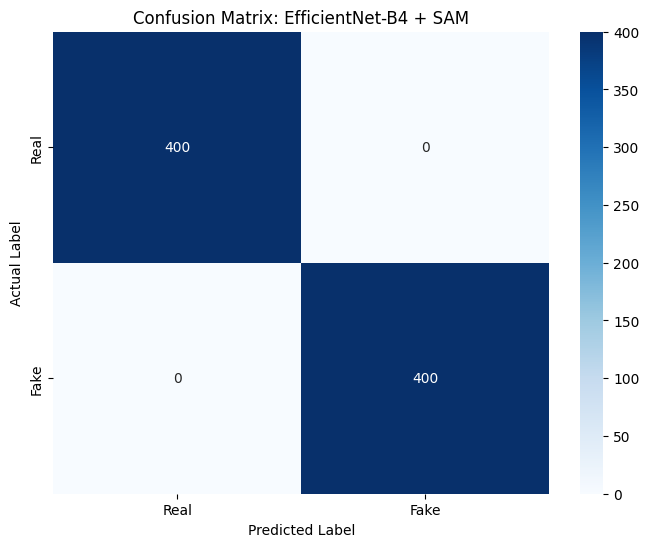

In [8]:
import torch
import torch.nn as nn
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
import os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc
from tqdm import tqdm

# 1. Re-declare Architecture & Dataset
class SpatialAttentionModule(nn.Module):
    def __init__(self):
        super(SpatialAttentionModule, self).__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        attention = torch.cat([avg_out, max_out], dim=1)
        attention = self.conv(attention)
        return x * self.sigmoid(attention)

class EfficientNetWithSAM(nn.Module):
    def __init__(self, num_classes=1):
        super(EfficientNetWithSAM, self).__init__()
        self.efficientnet = models.efficientnet_b4(weights=None)
        in_features = self.efficientnet.classifier[1].in_features
        self.efficientnet.classifier = nn.Identity()
        self.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.efficientnet(x)
        output = self.classifier(features)
        return output.squeeze()

class FaceForensicsDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.classes = ['real', 'fake']
        self.image_paths = []
        self.labels = []

        for idx, cls in enumerate(self.classes):
            cls_dir = os.path.join(data_dir, cls)
            if os.path.isdir(cls_dir):
                for img_name in os.listdir(cls_dir):
                    if img_name.endswith(('.png', '.jpg', '.jpeg')):
                        self.image_paths.append(os.path.join(cls_dir, img_name))
                        self.labels.append(idx)

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image = Image.open(self.image_paths[idx]).convert('RGB')
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.float32)

# 2. Setup Device, Transforms, and Load Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running evaluation on: {device}")

eval_transforms = transforms.Compose([
    transforms.Resize((380, 380)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

data_dir = '/content/drive/MyDrive/Dissertation/dataset'
dataset = FaceForensicsDataset(data_dir=data_dir, transform=eval_transforms)
# Using a larger batch size for faster evaluation
dataloader = DataLoader(dataset, batch_size=32, shuffle=True, num_workers=2)

model = EfficientNetWithSAM(num_classes=1).to(device)
weights_path = '/content/drive/MyDrive/Dissertation/efficientnet_sam_c23.pth'
model.load_state_dict(torch.load(weights_path, map_location=device))
model.eval()

# 3. Evaluation Loop
all_labels = []
all_preds = []

print("Starting batch inference for metrics generation...")
with torch.no_grad():
    for images, labels in tqdm(dataloader, desc="Evaluating"):
        images = images.to(device)
        outputs = model(images)

        # Store true labels and predicted probabilities
        all_labels.extend(labels.cpu().numpy())
        # Handle scalar output edge case for batch size 1
        if outputs.dim() == 0:
            all_preds.append(outputs.item())
        else:
            all_preds.extend(outputs.cpu().numpy())

# Convert to numpy arrays
y_true = np.array(all_labels)
y_scores = np.array(all_preds)
y_pred_binary = (y_scores >= 0.5).astype(int)

# 4. Plotting and Saving Metrics
save_dir = '/content/drive/MyDrive/Dissertation'

# --- Plot Confusion Matrix ---
cm = confusion_matrix(y_true, y_pred_binary)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Real', 'Fake'], yticklabels=['Real', 'Fake'])
plt.title('Confusion Matrix: EfficientNet-B4 + SAM')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
cm_path = os.path.join(save_dir, 'confusion_matrix.png')

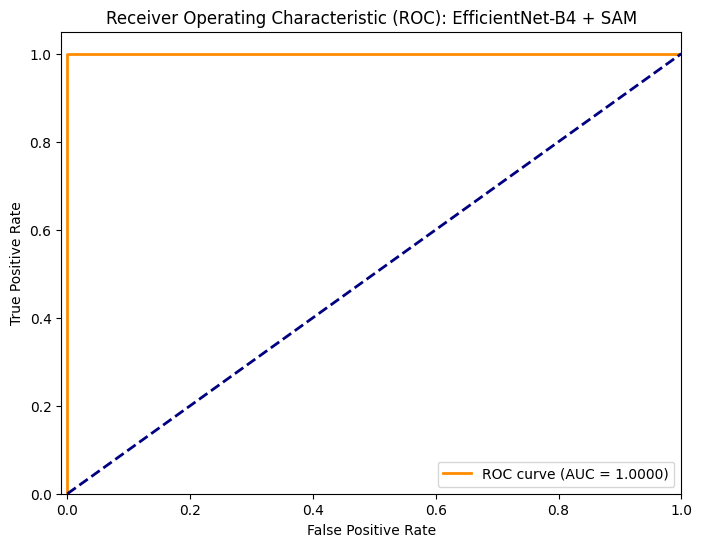

ROC Curve saved to /content/drive/MyDrive/Dissertation/roc_curve.png


In [9]:
import matplotlib.pyplot as plt
import os
from sklearn.metrics import roc_curve, auc

# Re-calculate using the data already in memory
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC): EfficientNet-B4 + SAM')
plt.legend(loc="lower right")

# Save and show
roc_path = '/content/drive/MyDrive/Dissertation/roc_curve.png'
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"ROC Curve saved to {roc_path}")

In [15]:
import torch
import torch.nn as nn
from torchvision import transforms, models
import cv2
from PIL import Image
from mtcnn import MTCNN
import os

# 1. Architecture Setup
class SpatialAttentionModule(nn.Module):
    def __init__(self):
        super(SpatialAttentionModule, self).__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        attention = torch.cat([avg_out, max_out], dim=1)
        attention = self.conv(attention)
        return x * self.sigmoid(attention)

class EfficientNetWithSAM(nn.Module):
    def __init__(self, num_classes=1):
        super(EfficientNetWithSAM, self).__init__()
        self.efficientnet = models.efficientnet_b4(weights=None)
        in_features = self.efficientnet.classifier[1].in_features
        self.efficientnet.classifier = nn.Identity()
        self.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes),
            nn.Sigmoid()
        )

    def forward(self, x):
        features = self.efficientnet(x)
        output = self.classifier(features)
        return output.squeeze()

# 2. Hardware and Weights
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = EfficientNetWithSAM(num_classes=1).to(device)
weights_path = '/content/drive/MyDrive/Dissertation/efficientnet_sam_c23.pth'
model.load_state_dict(torch.load(weights_path, map_location=device))
model.eval()

# 3. Preprocessing
inference_transforms = transforms.Compose([
    transforms.Resize((380, 380)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
detector = MTCNN()

# 4. Image Inference Function
def analyze_image(image_path):
    if not os.path.exists(image_path):
        print(f"File not found: {image_path}")
        return

    print(f"\nAnalyzing image: {os.path.basename(image_path)}")
    image = cv2.imread(image_path)

    if image is None:
        print("Error: Could not read image file.")
        return

    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    results = detector.detect_faces(rgb_image)

    if not results:
        print("Analysis failed: MTCNN could not detect a face in this image.")
        return

    # Crop the first detected face
    x, y, width, height = results[0]['box']
    margin = int(width * 0.1)
    x, y = max(0, x - margin), max(0, y - margin)
    x_end = min(image.shape[1], x + width + 2*margin)
    y_end = min(image.shape[0], y + height + 2*margin)

    cropped_face = rgb_image[y:y_end, x:x_end]

    if cropped_face.size != 0:
        pil_image = Image.fromarray(cropped_face)
        input_tensor = inference_transforms(pil_image).unsqueeze(0).to(device)

        with torch.no_grad():
            score = model(input_tensor).item()

        confidence = (score if score >= 0.5 else (1 - score)) * 100
        classification = "FAKE (Manipulated)" if score >= 0.5 else "REAL (Authentic)"

        print("-" * 40)
        print(f"FINAL VERDICT: {classification}")
        print(f"CONFIDENCE: {confidence:.2f}%")
        print(f"RAW SCORE (0=Real, 1=Fake): {score:.4f}")
        print("-" * 40)

# 5. TEST YOUR PHOTOS HERE
real_photo_path = '/content/drive/MyDrive/Dissertation/Real_photo.jpeg'
fake_photo_path = '/content/drive/MyDrive/Dissertation/fake_photo.jpeg' # Make sure to add .jpg or .png if your file has an extension!

print("Testing Real Photo:")
analyze_image(real_photo_path)

print("\nTesting Fake Photo:")
analyze_image(fake_photo_path)

Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.
Exception ignored in: <_io.BufferedReader>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/lz4/frame/__init__.py", line 753, in flush
    self._fp.flush()
ValueError: I/O operation on closed file.


Testing Real Photo:

Analyzing image: Real_photo.jpeg
----------------------------------------
FINAL VERDICT: REAL (Authentic)
CONFIDENCE: 93.50%
RAW SCORE (0=Real, 1=Fake): 0.0650
----------------------------------------

Testing Fake Photo:

Analyzing image: fake_photo.jpeg
----------------------------------------
FINAL VERDICT: FAKE (Manipulated)
CONFIDENCE: 95.01%
RAW SCORE (0=Real, 1=Fake): 0.9501
----------------------------------------
